In [44]:
import pandas as pd 
import numpy as np
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

In [45]:
url = 'https://github.com/git-iush/large_family/raw/refs/heads/main/data2.parquet'
df = pd.read_parquet(url)

In [46]:
df.head()

,SERIAL,HHWT,CLUSTER,STRATA,PERNUM,PERWT,NCHILD,SEX,AGE,MARST,...,BLACK,AIAN,API,OTHER,MULTR,HISP,EXPANSION,WELFARE,PRSNINC,YRSEDUC
0,4,4.0,2024000000041,280201,1,4.0,0,2,22,6,...,0,0,1,0,0,0,0,0.0,1000.0,13
1,9,74.0,2024000000091,280301,1,74.0,0,2,18,6,...,1,0,0,0,0,0,0,0.0,5100.0,12
2,12,55.0,2024000000121,160001,1,55.0,0,2,19,6,...,0,0,0,0,0,0,0,0.0,0.0,12
3,15,17.0,2024000000151,120201,1,17.0,0,2,19,6,...,0,0,0,0,0,0,0,0.0,6000.0,12
4,19,71.0,2024000000191,10001,1,71.0,0,2,23,6,...,0,0,0,0,0,0,0,0.0,0.0,13


In [47]:
df.shape

(720668, 76)

In [48]:
#Making HINSCAID and MEDICAID equal
df['MEDICAID'] = df['HINSCAID'] - 1

In [49]:
#model
model = smf.ols('NCHILD ~ MEDICAID * WELFARE + AGE', data=df).fit(cov_type='HC1')
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 NCHILD   R-squared:                       0.200
Model:                            OLS   Adj. R-squared:                  0.200
Method:                 Least Squares   F-statistic:                 5.784e+04
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:52:04   Log-Likelihood:            -1.0732e+06
No. Observations:              720668   AIC:                         2.146e+06
Df Residuals:                  720663   BIC:                         2.146e+06
Df Model:                           4                                         
Covariance Type:                  HC1                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -0.8519      0.003  

In [50]:
WelfareAVG = df['WELFARE'].mean()
ages = np.arange (18 , 46)

In [51]:
no_med  = pd.DataFrame({'AGE': ages, 'MEDICAID': 0, 'WELFARE': WelfareAVG})
yes_med = pd.DataFrame({'AGE': ages, 'MEDICAID': 1, 'WELFARE': WelfareAVG})

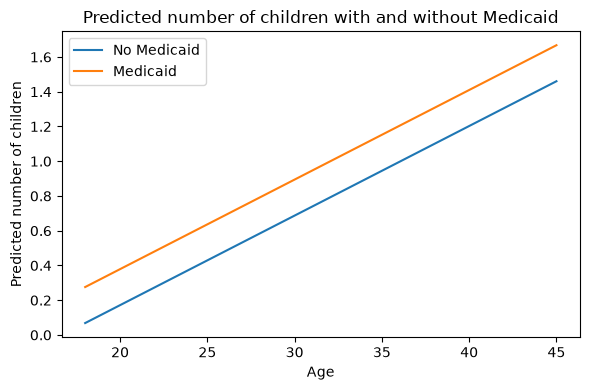

In [52]:
#Graph of no medicaid vs yes mediciad across the national level
plt.figure (figsize=(6, 4))

plt.plot (ages, model.predict(no_med),  label='No Medicaid')

plt.plot (ages, model.predict(yes_med), label='Medicaid')

plt.xlabel ('Age')

plt.ylabel ('Predicted number of children')

plt.title ('Predicted number of children with and without Medicaid')

plt.legend()

plt.tight_layout()

plt.show()

In [53]:
#Pooled regression with medicaid and welfare

In [54]:
model = smf.ols('NCHILD ~ MEDICAID * WELFARE + AGE', data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 NCHILD   R-squared:                       0.200
Model:                            OLS   Adj. R-squared:                  0.200
Method:                 Least Squares   F-statistic:                 4.509e+04
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:52:05   Log-Likelihood:            -1.0732e+06
No. Observations:              720668   AIC:                         2.146e+06
Df Residuals:                  720663   BIC:                         2.146e+06
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -0.8519      0.004  

In [55]:
#Pooled assignments
groups = [(0, 0, 'Neither'),
          (1, 0, 'Medicaid only'),
          (0, 1, 'Welfare only'),
          (1, 1, 'Medicaid & welfare')]

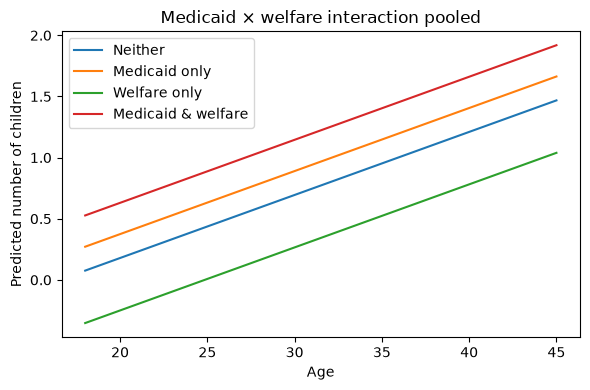

In [56]:
#New graph
plt.figure(figsize=(6, 4))
for m, w, label in groups:
    new = pd.DataFrame({'AGE': ages, 'MEDICAID': m, 'WELFARE': w})
    plt.plot(ages, model.predict(new), label=label)


plt.xlabel('Age')

plt.ylabel('Predicted number of children')

plt.title('Medicaid × welfare interaction pooled')

plt.legend()

plt.tight_layout()

plt.show()

In [60]:
#Race variables

In [66]:
import statsmodels.iolib.summary2 as sc

In [67]:
df['MEDICAID'] = df['HINSCAID'] - 1

df['race'] = 'white'
df.loc[df['BLACK'] == 1, 'race'] = 'black'
df.loc[df['AIAN'] == 1,  'race'] = 'aian'
df.loc[df['API'] == 1,   'race'] = 'asian_pi'
df.loc[df['OTHER'] == 1, 'race'] = 'other'
df.loc[df['MULTR'] == 1, 'race'] = 'multiracial'
df.loc[df['HISP'] == 1,  'race'] = 'hispanic'

In [68]:
races = df['race'].unique()
races

<ArrowStringArray>
['asian_pi', 'black', 'white', 'hispanic', 'multiracial', 'aian', 'other']
Length: 7, dtype: str

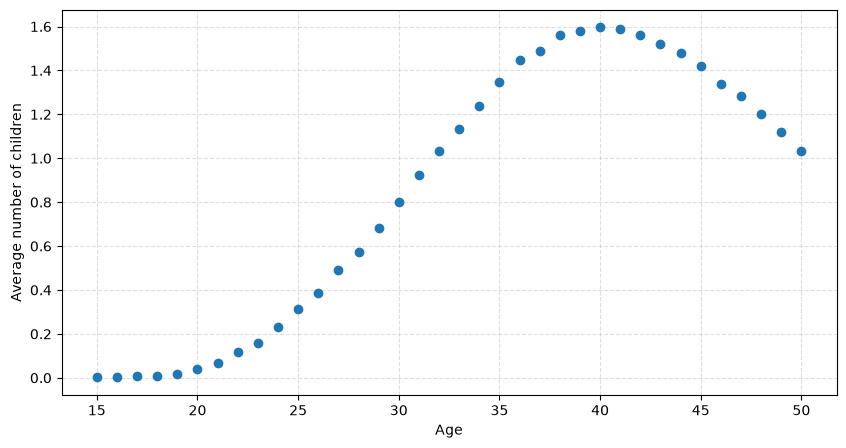

In [69]:
avg = df.groupby('AGE')['NCHILD'].mean()

plt.figure(figsize=(10,5))

plt.plot(avg.index, avg.values, 'o')
plt.xlabel('Age')
plt.ylabel('Average number of children')
plt.grid(alpha=0.4, ls='--')
plt.show()

In [70]:
m_cal = smf.ols('NCHILD ~ MEDICAID * WELFARE + AGE', data=df).fit(cov_type='HC1')

In [71]:
rt = sc.summary_col(results = [m_cal],
                    model_names = ['All'],
                    info_dict = {'No. Observations': lambda x: f'{int(x.nobs)}'},
                    regressor_order = ['Intercept', 'MEDICAID', 'WELFARE', 'MEDICAID:WELFARE', 'AGE'])
rt.tables[0].drop('R-squared Adj.', inplace=True)

print(rt)


                   All   
-------------------------
Intercept        -0.8519 
                 (0.0031)
MEDICAID         0.1954  
                 (0.0037)
WELFARE          -0.4288 
                 (0.0209)
MEDICAID:WELFARE 0.6844  
                 (0.0256)
AGE              0.0515  
                 (0.0001)
R-squared        0.2002  
No. Observations 720668  
Standard errors in
parentheses.


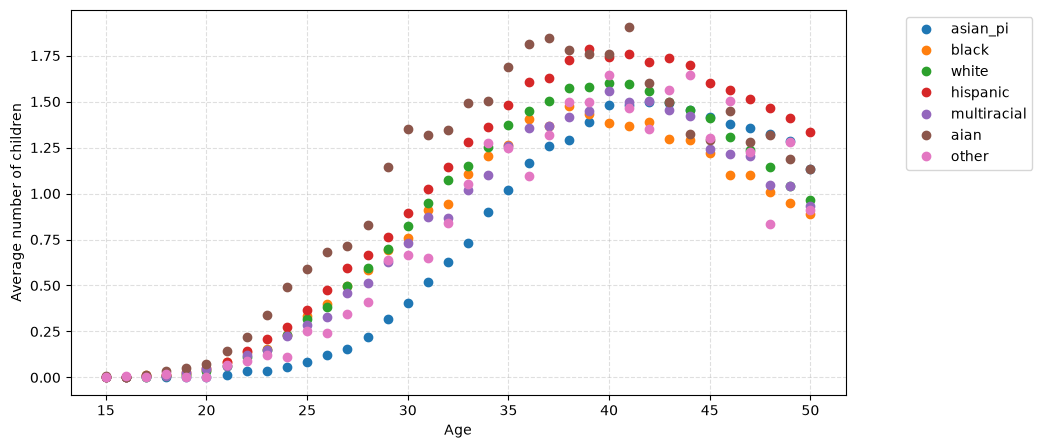

In [72]:
plt.figure(figsize=(10,5))

for r, clr in zip(races, ['C00','C01','C02','C03','C04','C05','C06']):
    avg_r = df[df['race']==r].groupby('AGE')['NCHILD'].mean()
    plt.plot(avg_r.index, avg_r.values, 'o', color=clr, label=r)

plt.xlabel('Age')
plt.ylabel('Average number of children')
plt.grid(alpha=0.4, ls='--')
plt.legend(ncol=1, bbox_to_anchor=(1.25,1))
plt.show()

In [73]:
reg = {}
for r in races:
    reg[r] = smf.ols('NCHILD ~ MEDICAID * WELFARE + AGE',
                     data=df[df['race']==r]).fit(cov_type='HC1')

In [74]:
reg['black'].params

Intercept          -0.755696
MEDICAID            0.276116
WELFARE            -0.397841
MEDICAID:WELFARE    0.723799
AGE                 0.044383
dtype: float64

In [75]:
reg['white'].params

Intercept          -0.769260
MEDICAID            0.150657
WELFARE            -0.625963
MEDICAID:WELFARE    0.810913
AGE                 0.049513
dtype: float64

In [76]:
rt = sc.summary_col(results = [m_cal] + [reg[i] for i in races],
                    model_names = ['All'] + [i.capitalize() for i in races],
                    info_dict = {'No. Observations': lambda x: f'{int(x.nobs)}'},
                    regressor_order = ['Intercept', 'MEDICAID', 'WELFARE', 'MEDICAID:WELFARE', 'AGE'])
rt.tables[0].drop('R-squared Adj.', inplace=True)

print(rt)


                   All    Asian_pi  Black    White   Hispanic Multiracial   Aian    Other  
-------------------------------------------------------------------------------------------
Intercept        -0.8519  -1.0968  -0.7557  -0.7693  -1.0751  -0.8485     -0.7598  -0.8770 
                 (0.0031) (0.0094) (0.0106) (0.0040) (0.0073) (0.0122)    (0.0388) (0.0419)
MEDICAID         0.1954   0.2366   0.2761   0.1507   0.2368   0.1943      0.2042   0.1117  
                 (0.0037) (0.0131) (0.0109) (0.0055) (0.0071) (0.0146)    (0.0346) (0.0510)
WELFARE          -0.4288  -0.2311  -0.3978  -0.6260  -0.1270  -0.5676     -0.5820  -0.6991 
                 (0.0209) (0.0808) (0.0554) (0.0237) (0.0510) (0.0528)    (0.1428) (0.1367)
MEDICAID:WELFARE 0.6844   0.5959   0.7238   0.8109   0.4054   0.8883      1.1567   1.4211  
                 (0.0256) (0.1162) (0.0671) (0.0313) (0.0593) (0.0780)    (0.2002) (0.2379)
AGE              0.0515   0.0549   0.0444   0.0495   0.0612   0.0493      0.051

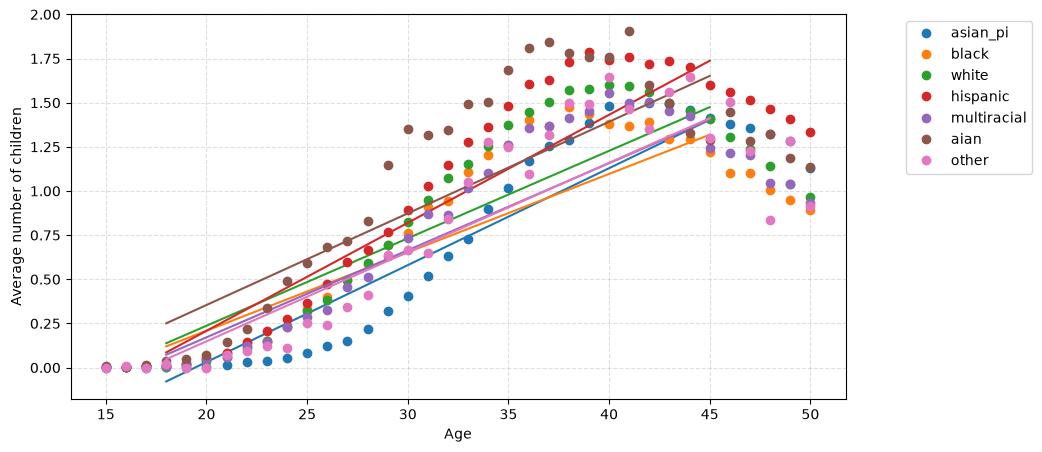

In [77]:
ages = np.arange(18, 46)

plt.figure(figsize=(10,5))

for r, clr in zip(races, ['C00','C01','C02','C03','C04','C05','C06']):
    avg_r = df[df['race']==r].groupby('AGE')['NCHILD'].mean()
    plt.plot(avg_r.index, avg_r.values, 'o', color=clr, label=r)

    new = pd.DataFrame({'AGE': ages,
                        'MEDICAID': df['MEDICAID'][df['race']==r].mean(),
                        'WELFARE': df['WELFARE'][df['race']==r].mean()})
    plt.plot(ages, reg[r].predict(new), '-', color=clr)

plt.xlabel('Age')
plt.ylabel('Average number of children')
plt.grid(alpha=0.4, ls='--')
plt.legend(ncol=1, bbox_to_anchor=(1.25,1))
plt.show()

In [78]:
#One-way fixed effects
ofe = smf.ols('NCHILD ~ MEDICAID * WELFARE + AGE + C(race, Treatment("white"))',
              data=df).fit(cov_type='HC1')

In [79]:
rt = sc.summary_col(results = [m_cal] + [reg[i] for i in races] + [ofe],
                    model_names = ['All'] + [i.capitalize() for i in races] +
                                  ['Race One-Way\nFixed-Effects'],
                    info_dict = {'No. Observations': lambda x: f'{int(x.nobs)}'},
                    regressor_order = ['Intercept', 'MEDICAID', 'WELFARE', 'MEDICAID:WELFARE', 'AGE'],
                    drop_omitted=True)
rt.tables[0].drop('R-squared Adj.', inplace=True)

print(rt)


                   All    Asian_pi  Black    White   Hispanic Multiracial   Aian    Other    Race One-Way
                                                                                            Fixed-Effects
---------------------------------------------------------------------------------------------------------
Intercept        -0.8519  -1.0968  -0.7557  -0.7693  -1.0751  -0.8485     -0.7598  -0.8770  -0.8500      
                 (0.0031) (0.0094) (0.0106) (0.0040) (0.0073) (0.0122)    (0.0388) (0.0419) (0.0033)     
MEDICAID         0.1954   0.2366   0.2761   0.1507   0.2368   0.1943      0.2042   0.1117   0.1912       
                 (0.0037) (0.0131) (0.0109) (0.0055) (0.0071) (0.0146)    (0.0346) (0.0510) (0.0037)     
WELFARE          -0.4288  -0.2311  -0.3978  -0.6260  -0.1270  -0.5676     -0.5820  -0.6991  -0.4337      
                 (0.0209) (0.0808) (0.0554) (0.0237) (0.0510) (0.0528)    (0.1428) (0.1367) (0.0207)     
MEDICAID:WELFARE 0.6844   0.5959   0.7238   0